# Quantum Vault

An educational E91-style quantum key distribution simulator with QBER, CHSH testing, key reconciliation, privacy amplification, and Quantum One-Time Pad encryption.

This notebook is a prototype for Qollab. It is not a production-secure QKD implementation.

In [1]:
import numpy as np
import pandas as pd
from quantum_vault import (
    ProtocolConfig,
    bell_pair_demo,
    bell_pair_circuit,
    run_experiment,
    print_result,
    sweep_eve_probability,
    plot_attack_sweep,
    plot_protocol_dashboard,
    qotp_demo,
    plot_qotp_state_comparison,
    # The interactive lab is imported in its own cell below.
)

## 1. Verify the Bell pair

The honest Z/Z Bell-pair circuit should produce mostly `00` and `11`. Each shot represents a fresh entangled pair.

In [2]:
print(bell_pair_circuit('Z', 'Z').draw())
bell_counts = bell_pair_demo(shots=1100)
print('Bell-pair counts:', bell_counts)

     ┌───┐     ┌───────┐┌─┐   
q_0: ┤ H ├──■──┤ Ry(0) ├┤M├───
     └───┘┌─┴─┐├───────┤└╥┘┌─┐
q_1: ─────┤ X ├┤ Ry(0) ├─╫─┤M├
          └───┘└───────┘ ║ └╥┘
c: 2/════════════════════╩══╩═
                         0  1 
Bell-pair counts: {'00': 531, '11': 569}


## 2. Run an honest channel

The protocol creates key rounds and CHSH test rounds, then calculates QBER, CHSH, reconciliation, privacy amplification, and the final acceptance decision.

In [3]:
honest_config = ProtocolConfig(
    rounds=1200,
    eve_probability=0.0,
    noise_probability=0.0,
    seed=7,
)
honest = run_experiment(honest_config)
print_result(honest)
honest['correlations']

QBER:             0.000
CHSH score:       2.860
Raw key length:   600
Final key length: 64
Accepted:         True


,alice_setting,bob_setting,samples,correlation
0,Z,B+,144,0.722222
1,Z,B-,164,0.743902
2,X,B+,143,0.622378
3,X,B-,149,-0.771812


## 3. Run an attacked channel

The educational Eve model replaces attacked rounds with classical correlations that cannot violate CHSH and adds disturbance to some key rounds.

In [4]:
attacked_config = ProtocolConfig(
    rounds=1200,
    eve_probability=0.75,
    noise_probability=0.0,
    seed=7,
)
attacked = run_experiment(attacked_config)
print_result(attacked)
attacked['correlations']

QBER:             0.182
CHSH score:       2.165
Raw key length:   600
Final key length: 0
Accepted:         False


,alice_setting,bob_setting,samples,correlation
0,Z,B+,144,0.847222
1,Z,B-,164,0.878049
2,X,B+,143,0.930070
3,X,B-,149,0.489933


## 4. Visualize Eve's effect

QBER should rise as Eve interferes. The CHSH score should move toward the classical limit of 2.

,eve_probability,qber,chsh,accepted,final_key_length
0,0.00,0.000000,2.779517,True,64
1,0.10,0.017766,2.550051,True,64
2,0.25,0.065000,2.770893,False,0
3,0.50,0.102902,2.247527,False,0
4,0.75,0.186869,2.263644,False,0
5,1.00,0.242188,2.000000,False,0


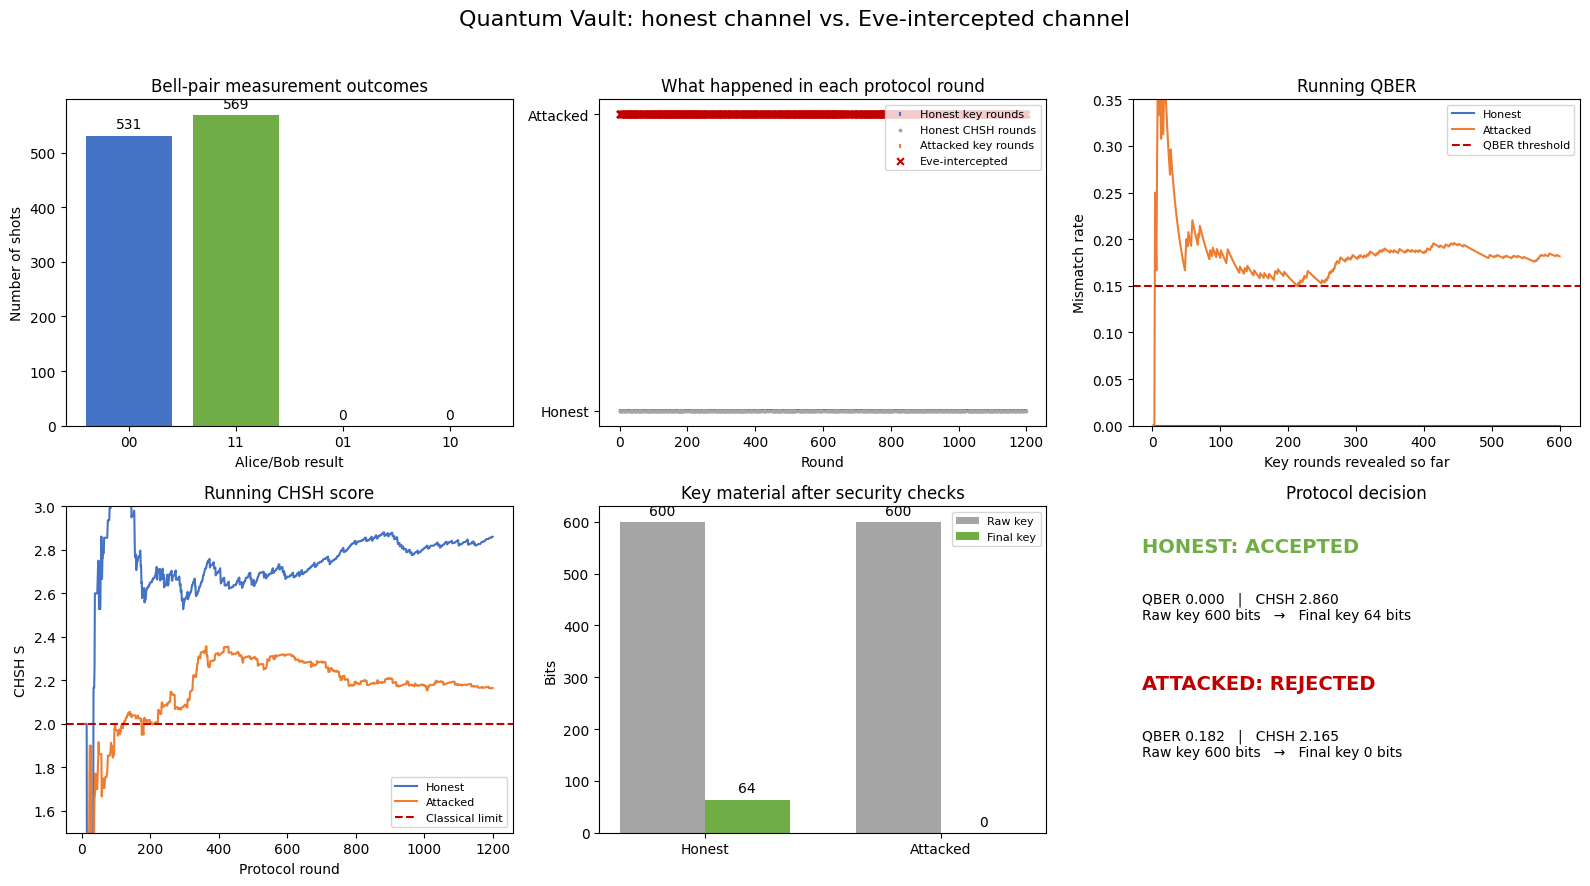

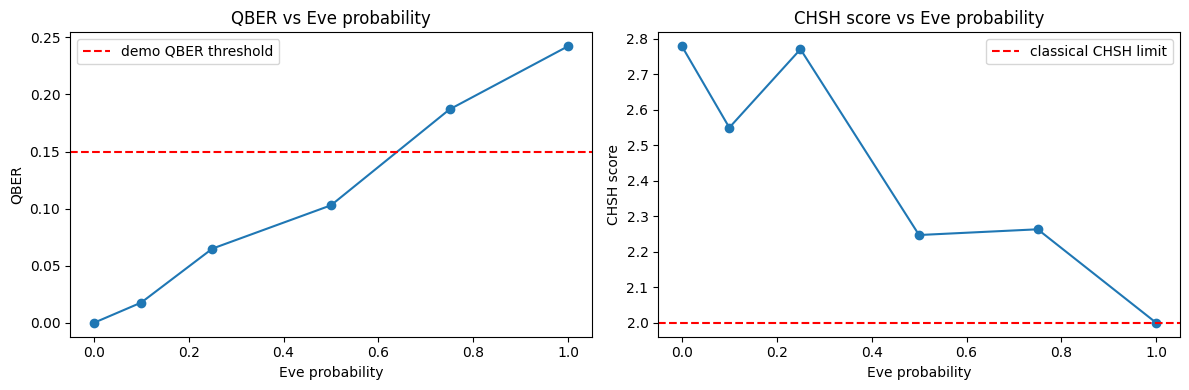

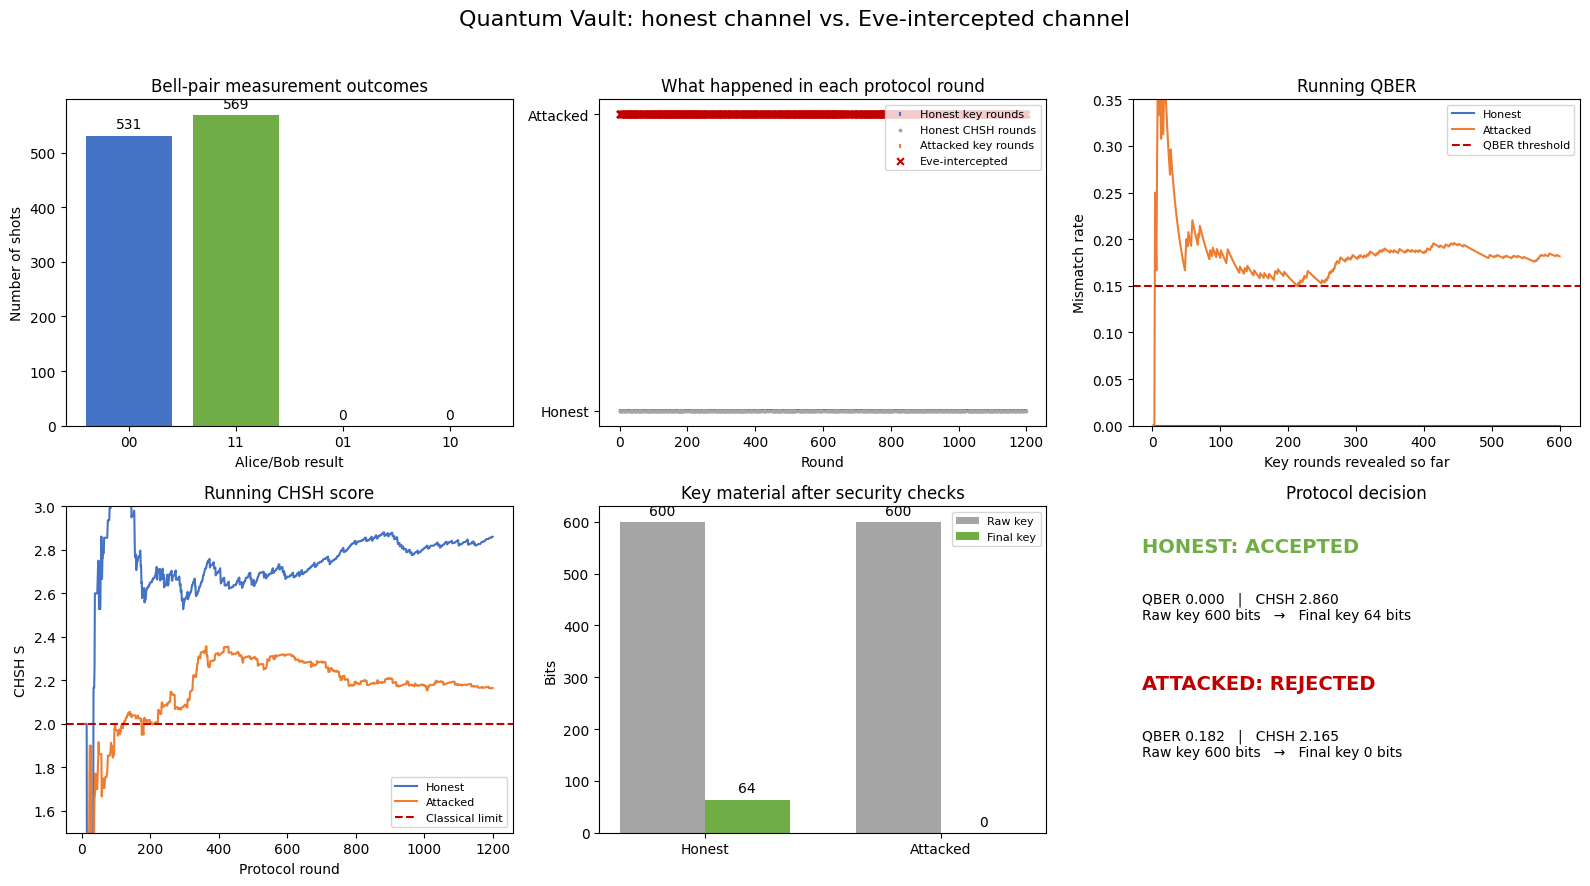

In [5]:
sweep = sweep_eve_probability(rounds=800, seed=11)
display(sweep)
plot_attack_sweep(sweep)
plot_protocol_dashboard(honest, attacked, bell_counts=bell_counts)[0]

## 5. QOTP demonstration

The final shared key encrypts the four-qubit message `|1>|+>|0>|0>`. Two key bits are consumed per message qubit.

QOTP key: 11011111
Key pairs: [[1, 1], [0, 1], [1, 1], [1, 1]]
Original circuit:
     ┌───┐
q_0: ┤ X ├
     ├───┤
q_1: ┤ H ├
     └───┘
q_2: ─────
          
q_3: ─────
          
Encrypted circuit:
     ┌───┐┌───┐┌───┐
q_0: ┤ X ├┤ X ├┤ Z ├
     ├───┤├───┤└───┘
q_1: ┤ H ├┤ Z ├─────
     ├───┤├───┤     
q_2: ┤ X ├┤ Z ├─────
     ├───┤├───┤     
q_3: ┤ X ├┤ Z ├─────
     └───┘└───┘     
Decrypted circuit:
     ┌───┐┌───┐┌───┐┌───┐┌───┐
q_0: ┤ X ├┤ X ├┤ Z ├┤ Z ├┤ X ├
     ├───┤├───┤├───┤└───┘└───┘
q_1: ┤ H ├┤ Z ├┤ Z ├──────────
     ├───┤├───┤├───┤┌───┐     
q_2: ┤ X ├┤ Z ├┤ Z ├┤ X ├─────
     ├───┤├───┤├───┤├───┤     
q_3: ┤ X ├┤ Z ├┤ Z ├┤ X ├─────
     └───┘└───┘└───┘└───┘     
Input statevector:
Statevector([0.        +0.j, 0.70710678+0.j, 0.        +0.j,
             0.70710678+0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.        +0.j,
             0.        +0.j, 0.        +0.j, 0.    

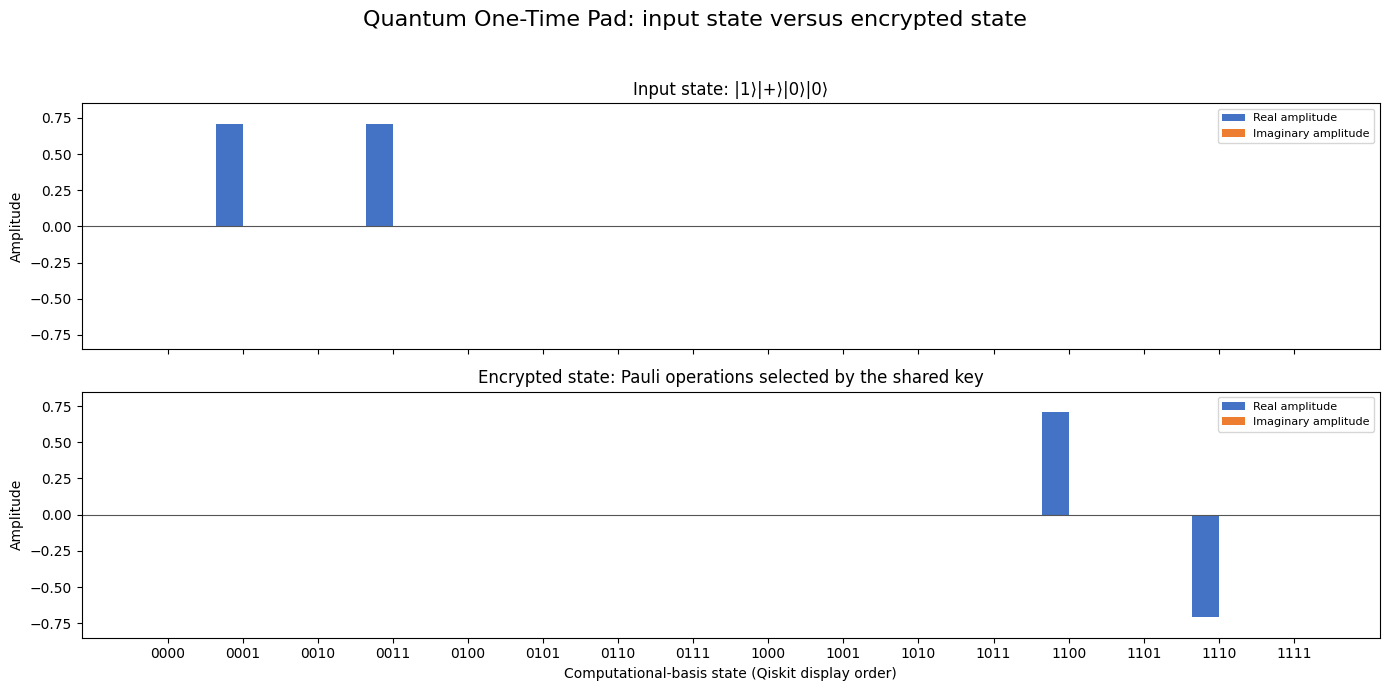

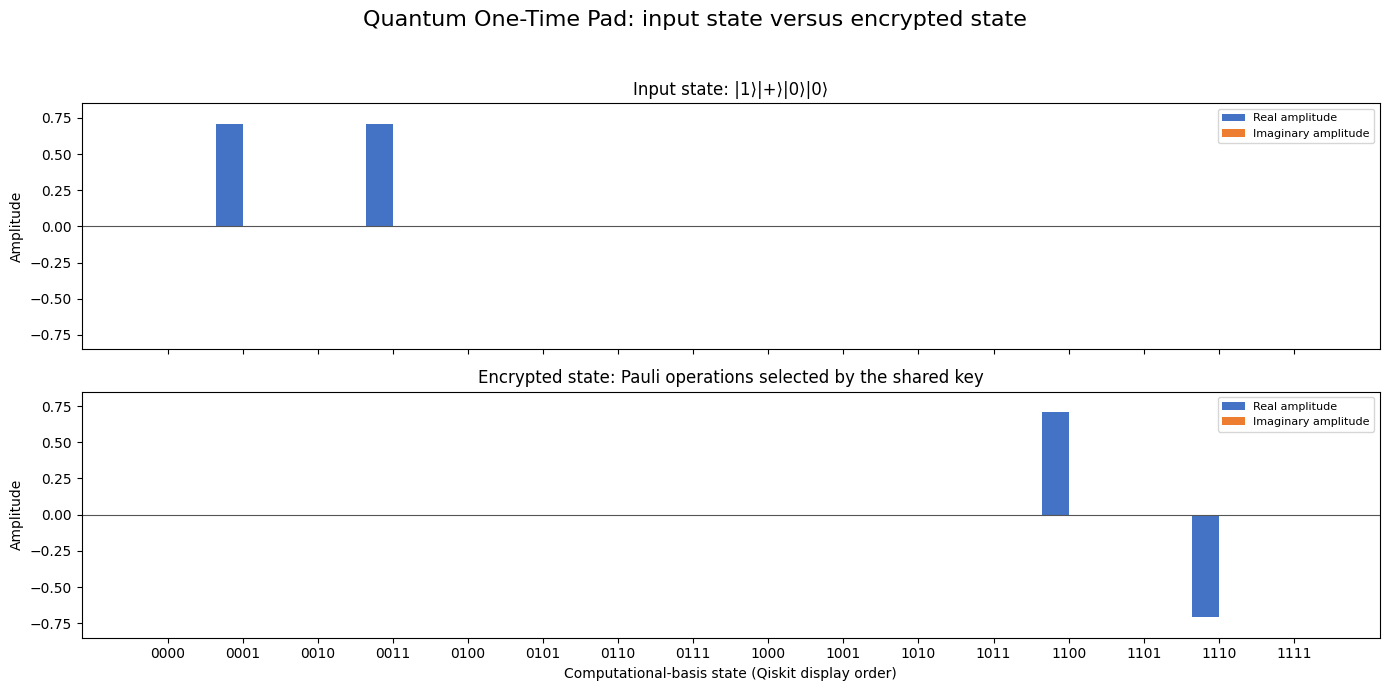

In [6]:
final_key = honest['final_key'][:8]
qotp = qotp_demo(final_key)
print('QOTP key:', ''.join(map(str, qotp['key_bits'])))
print('Key pairs:', qotp['key_pairs'])
print('Original circuit:')
print(qotp['original_circuit'].draw())
print('Encrypted circuit:')
print(qotp['encrypted_circuit'].draw())
print('Decrypted circuit:')
print(qotp['decrypted_circuit'].draw())
print('Input statevector:')
print(qotp['original_state'])
print('Encrypted statevector:')
print(qotp['encrypted_state'])
print('Message recovered:', np.allclose(
    qotp['original_state'].data,
    qotp['decrypted_state'].data,
))
plot_qotp_state_comparison(qotp)[0]

## 6. Interactive QuantumVault Lab

Use Learn mode for a guided walkthrough, Experiment mode to change Eve/noise settings, and Challenge mode to predict whether the key will be accepted. The Play control replays protocol rounds one at a time.

In [7]:
from quantum_vault_ui import build_interactive_lab
display(build_interactive_lab())

## 7. Suggested demo story

1. Show Bell-pair counts.
2. Run the honest channel and show a strong CHSH score.
3. Increase Eve probability and show QBER/CHSH change.
4. Show the protocol rejecting the compromised key.
5. Run QOTP only with an accepted key and show the original state is recovered.